In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


2. Exploratory Data Analysis & Preprocessing

In [26]:
print(df.isnull().sum())


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [27]:
X = df.drop(columns=['MedHouseVal']) 
y = df['MedHouseVal']

Correlation Heatmap (Exploratory Data Analysis)

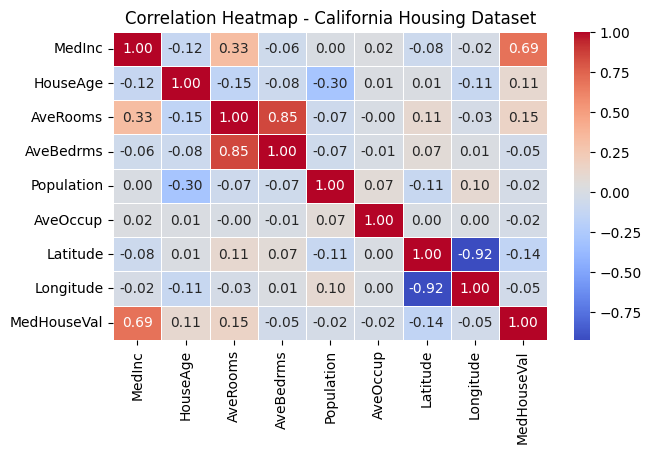

In [28]:
plt.figure(figsize=(7,4))

# Calculate correlation matrix
corr_matrix = df.corr()

# Plot heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap - California Housing Dataset')
plt.show()

In [29]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [30]:
# Feature Scaling 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

3. Train the Model

In [31]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

print('Model training complete!')

Model training complete!


 Feature Importance Bar Chart


C:\Users\prati\AppData\Local\Temp\ipykernel_17600\2576619655.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


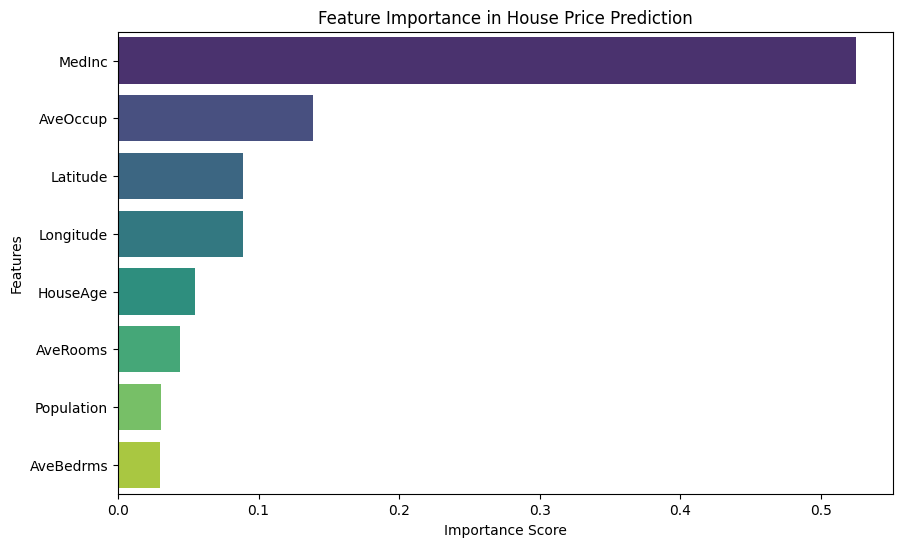

In [32]:
importances = rf_model.feature_importances_
features = X.columns

# Create a DataFrame for visualization
feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', y='Feature', data=feature_imp_df, palette='viridis'
)
plt.title('Feature Importance in House Price Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

4. Evaluate the Model

In [33]:
# Make predictions
y_pred = rf_model.predict(X_test_scaled)
print(y_pred)

[0.5095    0.74161   4.9232571 ... 4.7582187 0.71379   1.65772  ]


In [34]:
# Calculate metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R2 Score: {r2:.4f}')
print(f'RMSE: {rmse:.4f}')

R2 Score: 0.8053
RMSE: 0.5051


5. Save the Trained Model & Scaler

In [21]:
import joblib

In [12]:
joblib.dump(rf_model, 'house_price_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print('Model and scaler saved successfully!')

Model and scaler saved successfully!


Actual vs. Predicted House Prices 

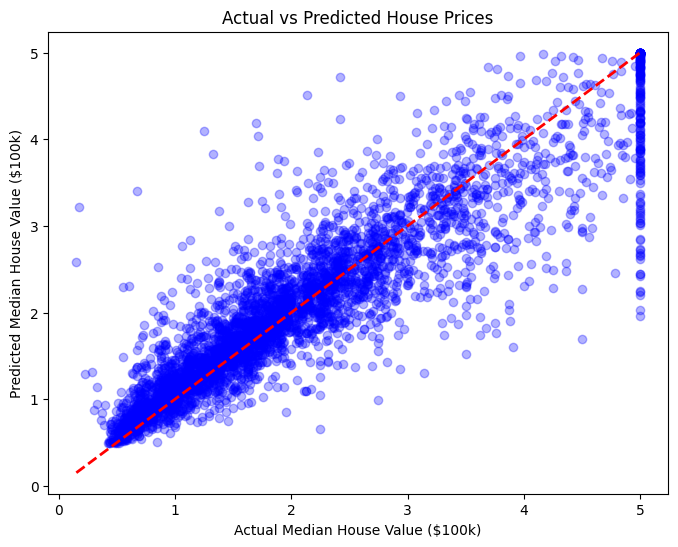

In [35]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue')

# Plot ideal line (where Actual = Predicted)
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2
)

plt.xlabel('Actual Median House Value ($100k)')
plt.ylabel('Predicted Median House Value ($100k)')
plt.title('Actual vs Predicted House Prices')

plt.show()